# Predicting Alzheimer's Disease Progression — Business & Data Understanding
**DSCI 4350 · Group 5 · First Checkpoint (Part 3)**
Christina Dames · Cinthia Ochoa Torre · Rayna Alexandre-Petrie

**Goal of this notebook:** explore the OASIS-2 longitudinal dataset, assess data quality, build the prediction target (*stable vs. declined at the next visit*), and document initial findings that guide data preparation and modeling in the next sprints (CRISP-DM: Business Understanding → Data Understanding).

## 1. Business Understanding → Data Science Goals

| Business objective | Data science goal |
|---|---|
| Know whether a patient's cognitive status will get worse | Binary classification: **stable (0) vs. declined (1)** at the next visit, using information from the earlier visit |
| Know which information is most useful | Compare 3 models (**MRI-only, metadata-only, combined**) using F1-score and ROC-AUC |
| Make predictions that work for new patients | **Patient-level** train/test split (no patient appears in both sets) |

**Decline definition:** the Clinical Dementia Rating (CDR) increases from one visit to the next (e.g., 0 → 0.5).

## 2. Data Acquisition

| Source | Content | Use |
|---|---|---|
| OASIS-2 longitudinal CSV (Kaggle: *MRI and Alzheimers*) | Demographics, cognitive scores, MRI-derived brain measures per visit | EDA + metadata model (this checkpoint) |
| OASIS-2 Longitudinal Scan Data (oasis-brains.org, ~18 GB raw 3D MRI) | Brain scans for the same patients and visits (matched by MRI ID) | CNN / MRI model (Sprint 2) |

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

# Find the CSV inside the Kaggle input folder
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename == 'oasis_longitudinal.csv':
            full_path = os.path.join(dirname, filename)

df = pd.read_csv(full_path)
print("Shape:", df.shape)
df.head()

Shape: (373, 15)


,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002,OAS2_0002_MR2,Demented,2,560,M,R,76,12,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002,OAS2_0002_MR3,Demented,3,1895,M,R,80,12,NaN,22.0,0.5,1698,0.701,1.034


### Column dictionary
Each **row is one visit** of one patient.

| Column | Meaning |
|---|---|
| Subject ID / MRI ID | Patient ID / ID of that visit's scan |
| Group | Nondemented, Demented, Converted (became demented during the study) |
| Visit, MR Delay | Visit number; days since the first visit |
| M/F, Hand, Age | Sex, dominant hand, age at visit |
| EDUC, SES | Years of education; socioeconomic status (1 = highest, 5 = lowest) |
| MMSE | Mini-Mental State Exam, 0–30 (lower = worse) |
| CDR | Clinical Dementia Rating: 0 normal, 0.5 very mild, 1 mild, 2 moderate |
| eTIV, nWBV, ASF | Intracranial volume; normalized whole-brain volume (drops with atrophy); atlas scaling factor |

## 3. Data Quality Report

### 3.1 Patients and visits

In [2]:
print("Patients:", df['Subject ID'].nunique())
print("Visits:", len(df))
print("\nNumber of patients by number of visits:")
print(df['Subject ID'].value_counts().value_counts().sort_index())

Patients: 150
Visits: 373

Number of patients by number of visits:
count
2    94
3    43
4     9
5     4
Name: count, dtype: int64


**Observation:** 150 patients, 373 visits. Every patient has **at least 2 visits** (94 have exactly 2), so all patients can be used for visit-to-next-visit prediction.

### 3.2 Missing values

In [3]:
missing = df.isnull().sum()
pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(1)})

,missing,percent
Subject ID,0,0.0
MRI ID,0,0.0
Group,0,0.0
Visit,0,0.0
MR Delay,0,0.0
M/F,0,0.0
Hand,0,0.0
Age,0,0.0
EDUC,0,0.0
SES,19,5.1


**Observation:** only **SES (19 missing, 5.1%)** and **MMSE (2 missing, 0.5%)** have missing values; all other columns are complete.

### 3.3 Summary statistics

In [4]:
df.describe().round(2)

,Visit,MR Delay,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,373.00,373.00,373.00,373.00,354.00,371.00,373.00,373.00,373.00,373.00
mean,1.88,595.10,77.01,14.60,2.46,27.34,0.29,1488.13,0.73,1.20
std,0.92,635.49,7.64,2.88,1.13,3.68,0.37,176.14,0.04,0.14
min,1.00,0.00,60.00,6.00,1.00,4.00,0.00,1106.00,0.64,0.88
25%,1.00,0.00,71.00,12.00,2.00,27.00,0.00,1357.00,0.70,1.10
50%,2.00,552.00,77.00,15.00,2.00,29.00,0.00,1470.00,0.73,1.19
75%,2.00,873.00,82.00,16.00,3.00,30.00,0.50,1597.00,0.76,1.29
max,5.00,2639.00,98.00,23.00,5.00,30.00,2.00,2004.00,0.84,1.59


In [5]:
print(df['Group'].value_counts(), "\n")
print(df['Hand'].value_counts(), "\n")
print(df['CDR'].value_counts().sort_index())

Group
Nondemented    190
Demented       146
Converted       37
Name: count, dtype: int64 

Hand
R    373
Name: count, dtype: int64 

CDR
0.0    206
0.5    123
1.0     41
2.0      3
Name: count, dtype: int64


**Observations**
- Age ranges from 60 to 98 (mean 77).
- MMSE minimum is **4** (typical range 27–30): a real severe case, kept as an outlier.
- **Hand** is constant (all right-handed) → no information.
- Only **3 visits have CDR = 2** → too few to draw conclusions for that level.
- **Group** is assigned using the patient's *whole* history, including future visits → using it as a feature would cause **data leakage**.
- MR Delay ranges from 0 to 2,639 days (~7 years) of follow-up.

### 3.4 Data preparation steps (Sprint 2)

| Issue | Action |
|---|---|
| SES: 19 missing | Fill with mode |
| MMSE: 2 missing | Fill with median |
| Hand: constant | Drop column |
| Group: uses future information | Exclude from features (leakage) |
| Time between visits varies | Add `days_to_next` feature |
| Visits of same patient are related | Patient-level train/test split |

## 4. Target Variable: Stable vs. Declined
For each visit, we look at the CDR of the **next** visit. If it increases, the pair is labeled **declined (1)**; otherwise **stable (0)**. The last visit of each patient has no next visit and is removed.

In [6]:
df = df.sort_values(['Subject ID', 'Visit'])

# CDR and days until the next visit of the same patient
df['CDR_next'] = df.groupby('Subject ID')['CDR'].shift(-1)
df['days_to_next'] = df.groupby('Subject ID')['MR Delay'].shift(-1) - df['MR Delay']

# Keep only visits that have a next visit
pairs = df.dropna(subset=['CDR_next']).copy()
pairs['declined'] = (pairs['CDR_next'] > pairs['CDR']).astype(int)

print("Number of visit pairs:", len(pairs))
print(pairs['declined'].value_counts())
print("Decline rate:", round(pairs['declined'].mean() * 100, 1), "%")

Number of visit pairs: 223
declined
0    192
1     31
Name: count, dtype: int64
Decline rate: 13.9 %


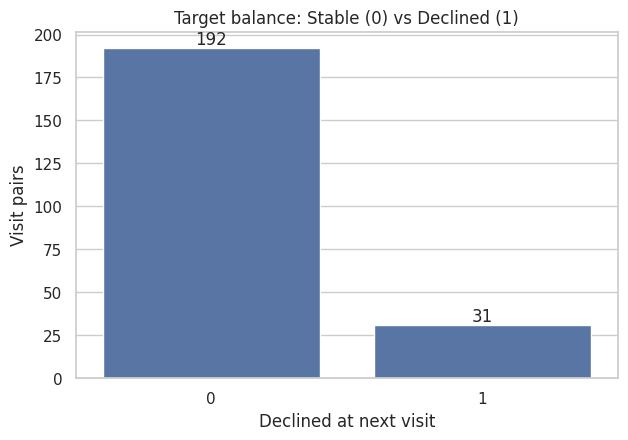

In [7]:
ax = sns.countplot(x='declined', data=pairs)
ax.bar_label(ax.containers[0])
plt.title('Target balance: Stable (0) vs Declined (1)')
plt.xlabel('Declined at next visit')
plt.ylabel('Visit pairs')
plt.show()

**Observation:** 223 visit pairs, only **31 declined (14%)** vs. 192 stable (86%). The target is **imbalanced**: a model that always predicts "stable" would reach 86% accuracy while finding zero decliners. → We will evaluate with **recall, F1-score and ROC-AUC**, not only accuracy.

## 5. Exploratory Data Analysis

### 5.1 Brain volume and dementia severity

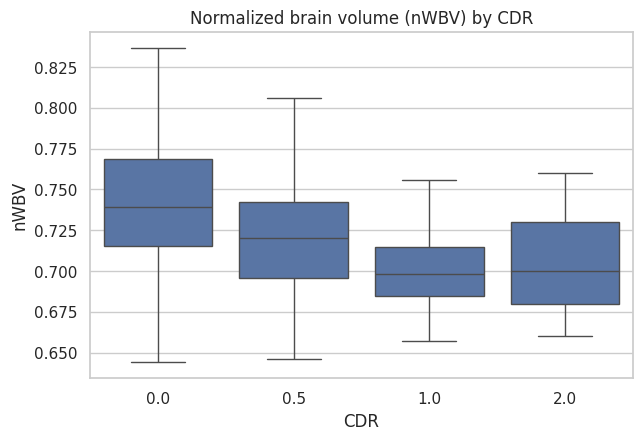

In [8]:
sns.boxplot(x='CDR', y='nWBV', data=df)
plt.title('Normalized brain volume (nWBV) by CDR')
plt.show()

**Observation:** median nWBV decreases as CDR increases (≈0.74 → 0.72 → 0.70): more dementia, more brain atrophy. MRI-derived features carry useful information, but boxes overlap heavily. (CDR 2 has only 3 visits.)

### 5.2 Age vs. brain volume

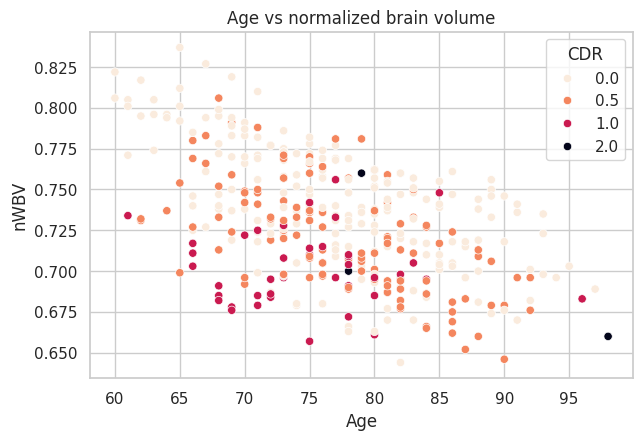

In [9]:
sns.scatterplot(x='Age', y='nWBV', hue='CDR', data=df, palette='rocket_r')
plt.title('Age vs normalized brain volume')
plt.show()

**Observation:** brain volume decreases with **age** even in healthy patients, and at the same age, patients with higher CDR tend to have lower nWBV. → Age must be included so the model does not confuse normal aging with dementia.

### 5.3 Does earlier brain volume predict decline?

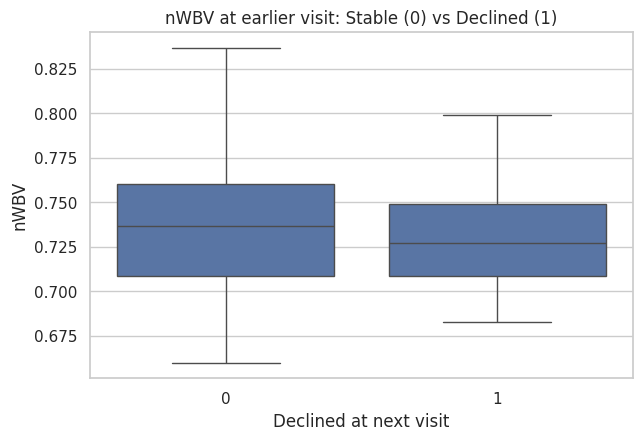

declined
0    0.736
1    0.727
Name: nWBV, dtype: float64


In [10]:
sns.boxplot(x='declined', y='nWBV', data=pairs)
plt.title('nWBV at earlier visit: Stable (0) vs Declined (1)')
plt.xlabel('Declined at next visit')
plt.show()

print(pairs.groupby('declined')['nWBV'].median().round(3))

**Observation:** patients who later declined had slightly lower brain volume (median ≈0.727 vs 0.736), but the distributions **overlap almost completely**. → MRI-derived volume alone is likely a weak predictor; combining it with patient metadata may add value (this is what our multimodal comparison tests).

### 5.4 Patient features: stable vs. declined

In [11]:
features = ['Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'nWBV', 'days_to_next']
pairs.groupby('declined')[features].mean().round(2)

,Age,EDUC,SES,MMSE,CDR,nWBV,days_to_next
declined,,,,,,,
0,75.99,14.63,2.47,27.86,0.24,0.74,708.79
1,76.65,14.71,2.22,26.90,0.31,0.73,780.45


In [12]:
rate = pd.crosstab(pairs['CDR'], pairs['declined'])
rate['decline_rate_%'] = (rate[1] / rate.sum(axis=1) * 100).round(1)
rate

declined,0,1,decline_rate_%
CDR,,,
0.0,118,15,11.3
0.5,57,13,18.6
1.0,17,3,15.0


**Observations**
- **MMSE** is lower in patients who later declined (≈26.9 vs 27.9).
- Patients starting at **CDR 0.5 decline more often (≈19%)** than those at CDR 0 (≈11%) — very mild symptoms often precede further decline.
- Age and education are very similar between groups.

### 5.5 Time between visits

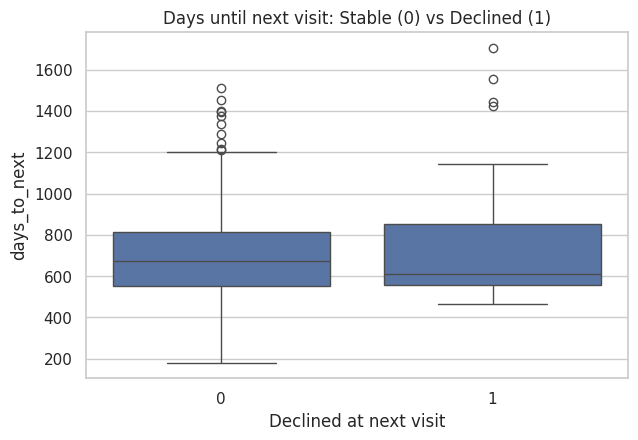

           mean  median    min
declined                      
0         709.0   674.0  182.0
1         780.0   610.0  465.0


In [13]:
sns.boxplot(x='declined', y='days_to_next', data=pairs)
plt.title('Days until next visit: Stable (0) vs Declined (1)')
plt.xlabel('Declined at next visit')
plt.show()

print(pairs.groupby('declined')['days_to_next'].agg(['mean', 'median', 'min']).round(0))

**Observation:** mean gap is slightly higher for decliners (780 vs 709 days), but the median is lower, and the difference is driven by a few outliers (>1,400 days). Time between visits does not separate the groups well, but it is kept as a feature because patients were followed for different lengths of time.

## 6. Initial Findings

1. **Small longitudinal dataset:** 150 patients, 373 visits → only **223 visit pairs** for modeling.
2. **Imbalanced target:** 31 declined (14%) vs 192 stable → use F1, recall and ROC-AUC with a patient-level split.
3. **Brain volume drops with dementia and age,** but at the earlier visit decliners are only slightly lower → MRI alone is likely weak; combining sources may help.
4. **MMSE and starting CDR are the most informative features:** lower MMSE and CDR 0.5 are associated with later decline.
5. **Data source issue resolved:** the reference Kaggle notebooks use OASIS-1 (one scan per person, no follow-up). We located the **OASIS-2 longitudinal scans**, which match our CSV visits by MRI ID, so the MRI-only and combined models are feasible.

## 7. Next Steps (Sprint 2)
- Apply the data preparation steps from Section 3.4.
- Download the OASIS-2 scans and set up MRI preprocessing for the CNN.
- Build the patient-level train/test split and baseline metadata-only model.